## All you need is love… And a pet!

<img src="img/dataset-cover.jpg" width="920">

Here we are going to build a classifier to predict whether an animal from an animal shelter will be adopted or not (aac_intakes_outcomes.csv, available at: https://www.kaggle.com/aaronschlegel/austin-animal-center-shelter-intakes-and-outcomes/version/1#aac_intakes_outcomes.csv). You will be working with the following features:

1. *animal_type:* Type of animal. May be one of 'cat', 'dog', 'bird', etc.
2. *intake_year:* Year of intake
3. *intake_condition:* The intake condition of the animal. Can be one of 'normal', 'injured', 'sick', etc.
4. *intake_number:* The intake number denoting the number of occurrences the animal has been brought into the shelter. Values higher than 1 indicate the animal has been taken into the shelter on more than one occasion.
5. *intake_type:* The type of intake, for example, 'stray', 'owner surrender', etc.
6. *sex_upon_intake:* The gender of the animal and if it has been spayed or neutered at the time of intake
7. *age_upon\_intake_(years):* The age of the animal upon intake represented in years
8. *time_in_shelter_days:* Numeric value denoting the number of days the animal remained at the shelter from intake to outcome.
9. *sex_upon_outcome:* The gender of the animal and if it has been spayed or neutered at time of outcome
10. *age_upon\_outcome_(years):* The age of the animal upon outcome represented in years
11. *outcome_type:* The outcome type. Can be one of ‘adopted’, ‘transferred’, etc.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import scipy as sp
from itertools import combinations 
import ast
from sklearn.linear_model import LogisticRegression
import seaborn as sn
%matplotlib inline

data_folder = './data/'

### A) Load the dataset and convert categorical features to a suitable numerical representation (use dummy-variable encoding). 
- Split the data into a training set (80%) and a test set (20%). Pair each feature vector with the corresponding label, i.e., whether the outcome_type is adoption or not. 
- Standardize the values of each feature in the data to have mean 0 and variance 1.

The use of external libraries is not permitted in part A, except for numpy and pandas. 
You can drop entries with missing values.

In [2]:
columns = ['animal_type', 'intake_year', 'intake_condition', 'intake_number', 'intake_type', 'sex_upon_intake', \
          'age_upon_intake_(years)', 'time_in_shelter_days', 'sex_upon_outcome', 'age_upon_outcome_(years)', \
          'outcome_type']
original_data = pd.read_csv(data_folder+'aac_intakes_outcomes.csv', usecols=columns)

In [3]:
#Check for completeness of data and NAN's
print('The length of the data with all rows is : {}'.format(len(original_data)))
original_data.dropna(inplace=True)
print('The length of the data without the rows with nan value is: {}'.format(len(original_data)))

The length of the data with all rows is : 79672
The length of the data without the rows with nan value is: 79661


turns the multi-class outcome_type column into a binary target, adopted yes/no, which can then be used for classification.

independent copy of the DataFrame. Without .copy(), data_features = original_data would just be a second name for the same object, and the changes below (adding and dropping columns) would also change original_data. The copy keeps the raw data untouched.




data_features.outcome_type is the column with values like 'Adoption', 'Transfer', 'Return_to_owner', 'Euthanasia', … (the same as data_features['outcome_type']).
.apply(f) runs the function f on every value of the column.
lambda r: 1 if r=='Adoption' else 0 is a small anonymous function. For each value r it returns 1 if it's 'Adoption' and 0 otherwise. It's the same one-line if/else as "YES" if ... else "NO" before.
The result is stored in a new column adopted. That's your label y: 1 = adopted, everything else = 0.

In [4]:
data_features = original_data.copy()
data_features['adopted'] = data_features.outcome_type.apply(lambda r: 1 if r=='Adoption' else 0)
data_features.drop("outcome_type", axis = 1, inplace=True)
data_features.head()

,sex_upon_outcome,age_upon_outcome_(years),animal_type,intake_condition,intake_type,sex_upon_intake,age_upon_intake_(years),intake_year,intake_number,time_in_shelter_days,adopted
0,Neutered Male,10.0,Dog,Normal,Stray,Neutered Male,10.0,2017,1.0,0.588194,0
1,Neutered Male,7.0,Dog,Normal,Public Assist,Neutered Male,7.0,2014,2.0,1.259722,0
2,Neutered Male,6.0,Dog,Normal,Public Assist,Neutered Male,6.0,2014,3.0,1.113889,0
3,Neutered Male,10.0,Dog,Normal,Owner Surrender,Neutered Male,10.0,2014,1.0,4.970139,0
4,Neutered Male,16.0,Dog,Injured,Public Assist,Neutered Male,16.0,2013,1.0,0.119444,0


This removes the original outcome_type column. axis=1 means drop a column; axis=0 would drop rows.
inplace=True changes data_features directly instead of returning a new DataFrame. It's the same as data_features = data_features.drop(columns="outcome_type").

In [5]:
#Split the data set 80/20 percentage ratio
def split_set(data_to_split, ratio=0.8):
    mask = np.random.rand(len(data_to_split)) < ratio
    return [data_to_split[mask].reset_index(drop=True), data_to_split[~mask].reset_index(drop=True)]

np.random.rand(n) draws n random numbers, uniform between 0 and 1, one per row.
< ratio compares each number to 0.8. That gives a boolean array, True if the number < 0.8 and False otherwise.
**Since the numbers are uniform, each row has an 80% chance of getting True.**


data_to_split[mask] keeps the rows where the mask is True. That's the training set (~80%).
~mask inverts the mask (True ↔ False), so data_to_split[~mask] gives all the other rows. That's the test set (~20%).
Every row ends up in exactly one of the two sets, so there's no overlap.
.reset_index(drop=True) renumbers the rows 0, 1, 2, …. drop=True throws the old index away instead of keeping it as a new column. Without it, the train set would have gaps in its index like 0, 2, 3, 5, …
It returns a list of 2 DataFrames, so you can unpack them: train, test = split_set(data_features)

Two things to note
The split is only roughly 80/20. Each row is a coin flip with p = 0.8, so with 1000 rows you might get 793 / 207. If you need an exact split, shuffle and cut instead.
No seed. Every run gives a different split, and so slightly different results. Call np.random.seed(0) before it if you want reproducibility, as with random_state=0.

You're right: this strategy doesn't guarantee 80/20. Each row is an independent coin flip with P(train) = 0.8, so the number of training rows follows a binomial distribution, Bin(n, 0.8).

How far off can it be? The standard deviation of the train fraction is

$$\sqrt{\frac{0.8 \cdot 0.2}{n}}$$

n = 100 → ±4% (e.g. 76/24 is quite normal)
n = 10,000 → ±0.4%
n = 100,000 → ±0.13%

So it's unreliable for small datasets and fine for large ones (law of large numbers). The animal shelter dataset has tens of thousands of rows, so the solution's split ends up very close to 80/20 and it doesn't matter there.

**Exact splitting:** shuffle, then cut
Instead of flipping a coin per row, shuffle the row order randomly and take the first 80%:




In [6]:
def split_set_exact(data_to_split, ratio=0.8, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(data_to_split))   # random order of 0..n-1
    n_train = int(ratio * len(data_to_split))   # exact count
    train = data_to_split.iloc[idx[:n_train]].reset_index(drop=True)
    test  = data_to_split.iloc[idx[n_train:]].reset_index(drop=True)
    return train, test


rng.permutation(n) returns the numbers 0 … n−1 in random order, each exactly once.
idx[:n_train] takes the first 80% of those positions and idx[n_train:] takes the rest. There's no overlap, and every row is used.
.iloc selects rows by position, which works even if the index isn't 0…n−1.

**Pandas shortcut:**


train = data_to_split.sample(frac=0.8, random_state=0)
test  = data_to_split.drop(train.index)
Or sklearn, which does the same shuffle-and-cut:


train, test = train_test_split(data_to_split, test_size=0.2, random_state=0)
train_test_split also has stratify=y. It keeps the class proportions (e.g. the adoption rate) the same in train and test, which is useful when one class is rare.

In [7]:
[train, test] = split_set(data_features)

In [8]:
categorical_columns = ['sex_upon_outcome', 'animal_type', 'intake_condition',
                       'intake_type', 'sex_upon_intake']
train_categorical = pd.get_dummies(train, columns=categorical_columns)
train_categorical.columns

Index(['age_upon_outcome_(years)', 'age_upon_intake_(years)', 'intake_year',
       'intake_number', 'time_in_shelter_days', 'adopted',
       'sex_upon_outcome_Intact Female', 'sex_upon_outcome_Intact Male',
       'sex_upon_outcome_Neutered Male', 'sex_upon_outcome_Spayed Female',
       'sex_upon_outcome_Unknown', 'animal_type_Bird', 'animal_type_Cat',
       'animal_type_Dog', 'animal_type_Other', 'intake_condition_Aged',
       'intake_condition_Feral', 'intake_condition_Injured',
       'intake_condition_Normal', 'intake_condition_Nursing',
       'intake_condition_Other', 'intake_condition_Pregnant',
       'intake_condition_Sick', 'intake_type_Euthanasia Request',
       'intake_type_Owner Surrender', 'intake_type_Public Assist',
       'intake_type_Stray', 'intake_type_Wildlife',
       'sex_upon_intake_Intact Female', 'sex_upon_intake_Intact Male',
       'sex_upon_intake_Neutered Male', 'sex_upon_intake_Spayed Female',
       'sex_upon_intake_Unknown'],
      dtype='str')

This cell does one-hot encoding: it turns the categorical (text) columns into numeric 0/1 columns, because ML models can only work with numbers.


categorical_columns = ['sex_upon_outcome', 'animal_type', 'intake_condition',
                       'intake_type', 'sex_upon_intake']
This lists the columns that contain categories (strings) rather than numbers.


train_categorical = pd.get_dummies(train, columns=categorical_columns)
For each of those columns, get_dummies creates one new column per category value, filled with 1/True where that row has the value and 0/False otherwise. It then removes the original text column. All the other columns (age, adopted, …) stay as they are.

Example for animal_type:

animal_type	→	animal_type_Cat	animal_type_Dog	animal_type_Other
Dog		0	1	0
Cat		1	0	0
Dog		0	1	0
The new names are columnname_value. You saw the same thing with Titanic, where sex became sex_female / sex_male.

Why not just encode it as Cat=0, Dog=1, Other=2? Then the model would treat the categories as ordered numbers, as if Other > Dog > Cat and Dog were "between" Cat and Other. One-hot avoids inventing an order that doesn't exist.


train_categorical.columns
This shows the resulting column names, so you can check what was created.



The features in the testing set must be matched with the traning set.

In [9]:
# Make sure we use only the features available in the training set
test_categorical = pd.get_dummies(test, columns=categorical_columns)[train_categorical.columns]

Note: If a rare category appears only in train (e.g. one intake_condition value that ended up in no test row), the test set won't have that dummy column and you get a KeyError. The safer version fills missing columns with 0:


test_categorical = pd.get_dummies(test, columns=categorical_columns) \
                     .reindex(columns=train_categorical.columns, fill_value=0)
It also drops any category that appears only in test, which the model has never seen anyway.

In [10]:
train_label=train_categorical.adopted
train_features = train_categorical.drop('adopted', axis=1)
print('Length of the train dataset : {}'.format(len(train)))

test_label=test_categorical.adopted
test_features = test_categorical.drop('adopted', axis=1)
print('Length of the test dataset : {}'.format(len(test)))

Length of the train dataset : 63756
Length of the test dataset : 15905


This block separates the label (y) from the features (X), for both the training and the test set.


train_label = train_categorical.adopted
This takes the adopted column (0/1) as a Series. That's y_train, what the model should learn to predict. It's the same as train_categorical['adopted'].


train_features = train_categorical.drop('adopted', axis=1)
This is every column except adopted: that's X_train, the input the model sees.

axis=1 drops a column.
No inplace=True here, so drop returns a new DataFrame and train_categorical itself stays unchanged.
Removing adopted from X is essential. Otherwise the answer would be among the inputs, which is the same leakage problem as with outcome_type before.

print('Length of the train dataset : {}'.format(len(train)))
This prints the number of rows. '{}'.format(x) puts x into the {}. The modern equivalent is f'Length of the train dataset : {len(train)}'. It's a quick sanity check that you got about 80% / 20%.

The next three lines do exactly the same for the test set: test_label is y_test and test_features is X_test.

Result: the four standard objects
Features (X)	Label (y)
Train	train_features	train_label
Test	test_features	test_label
They'll be used like this:


model.fit(train_features, train_label)       # learn only from train
pred = model.predict(test_features)          # predict on unseen data
compare pred with test_label → accuracy, precision, recall …

### Standardization
This block standardizes every feature to mean 0 and standard deviation 1 (the z-score), the same idea as standardizing in exercise 4.


means = train_features.mean()
stddevs = train_features.std()
This computes the mean and standard deviation of each column, using the training set only. Each result is a Series indexed by column name, e.g. means['age_upon_outcome'].

In [11]:
means = train_features.mean()
stddevs = train_features.std()

train_features_std = pd.DataFrame()
for c in train_features.columns:
    train_features_std[c] = (train_features[c]-means[c])/stddevs[c]

# Use the mean and stddev of the training set
test_features_std = pd.DataFrame()
for c in test_features.columns:
    test_features_std[c] = (test_features[c]-means[c])/stddevs[c]

train_features_std.head()

,age_upon_outcome_(years),age_upon_intake_(years),intake_year,intake_number,time_in_shelter_days,sex_upon_outcome_Intact Female,sex_upon_outcome_Intact Male,sex_upon_outcome_Neutered Male,sex_upon_outcome_Spayed Female,sex_upon_outcome_Unknown,...,intake_type_Euthanasia Request,intake_type_Owner Surrender,intake_type_Public Assist,intake_type_Stray,intake_type_Wildlife,sex_upon_intake_Intact Female,sex_upon_intake_Intact Male,sex_upon_intake_Neutered Male,sex_upon_intake_Spayed Female,sex_upon_intake_Unknown
0,2.725242,2.743953,1.199812,-0.276089,-0.389955,-0.362528,-0.371552,1.344568,-0.689059,-0.303701,...,-0.057211,-0.483735,-0.257756,0.652894,-0.213721,-0.649841,-0.680089,2.281156,-0.405469,-0.303701
1,1.338628,1.353942,-1.100288,4.069626,-0.377302,-0.362528,-0.371552,1.344568,-0.689059,-0.303701,...,-0.057211,-0.483735,3.879578,-1.531619,-0.213721,-0.649841,-0.680089,2.281156,-0.405469,-0.303701
2,2.725242,2.743953,-1.100288,-0.276089,-0.284484,-0.362528,-0.371552,1.344568,-0.689059,-0.303701,...,-0.057211,2.067216,-0.257756,-1.531619,-0.213721,-0.649841,-0.680089,2.281156,-0.405469,-0.303701
3,4.805163,4.828970,-1.866988,-0.276089,-0.401238,-0.362528,-0.371552,1.344568,-0.689059,-0.303701,...,-0.057211,-0.483735,3.879578,-1.531619,-0.213721,-0.649841,-0.680089,2.281156,-0.405469,-0.303701
4,4.458509,4.481467,-1.100288,-0.276089,-0.253478,-0.362528,-0.371552,1.344568,-0.689059,-0.303701,...,-0.057211,-0.483735,3.879578,-1.531619,-0.213721,-0.649841,-0.680089,2.281156,-0.405469,-0.303701


This starts with an empty DataFrame and, for each column, fills in the z-score:

$$z = \frac{x - \mu}{\sigma}$$

Subtracting the mean centres the column around 0.
Dividing by the std makes the spread 1.
A value of z = 2 means "2 standard deviations above the training mean".

test_features_std = pd.DataFrame()
for c in test_features.columns:
    test_features_std[c] = (test_features[c] - means[c]) / stddevs[c]
This is the important part: the test set is standardized with the train mean and std, not its own. Two reasons:

No leakage. The test set stands in for future, unseen data. You can't compute statistics on future data before it arrives, so everything you "learn", including preprocessing parameters, must come from train only.
Same scale. The model learned its coefficients on the scale defined by the train statistics. The test data has to be transformed the same way, or the inputs would mean something different to the model.

**IMPORTANT**: test set is standardized with the train mean and std, not its own.

**Why standardize at all?**
The features have very different scales: age in days (hundreds or thousands) versus dummies (0/1). With regularized logistic regression (sklearn uses L2 by default), the penalty hits all coefficients equally, so the scale affects the result.
After standardizing, coefficients are comparable: a larger |coef| means a more important feature, just like in exercise 4.
Gradient-based solvers converge faster.
Distance-based models like k-NN need it. Otherwise the feature with the largest numbers dominates the distance.

### B) Train a logistic regression classifier on your training set. Logistic regression returns probabilities as predictions, so in order to arrive at a binary prediction, you need to put a threshold on the predicted probabilities. 
- For the decision threshold of 0.5, present the performance of your classifier on the test set by displaying the confusion matrix. Based on the confusion matrix, manually calculate accuracy, precision, recall, and F1-score with respect to the positive and the negative class. 

compute_confusion_matrix counts the four kinds of right and wrong predictions.
plot_confusion_matrix draws those counts as a heatmap.
compute_all_score derives the metrics: accuracy, precision, recall, F1.

In [12]:
def compute_confusion_matrix(true_label, prediction_proba, decision_threshold=0.5): 
    
    predict_label = (prediction_proba[:,1]>decision_threshold).astype(int)   
                                                                                                                       
    TP = np.sum(np.logical_and(predict_label==1, true_label==1))
    TN = np.sum(np.logical_and(predict_label==0, true_label==0))
    FP = np.sum(np.logical_and(predict_label==1, true_label==0))
    FN = np.sum(np.logical_and(predict_label==0, true_label==1))
    
    confusion_matrix = np.asarray([[TP, FP],
                                    [FN, TN]])
    return confusion_matrix


1. compute_confusion_matrix

def compute_confusion_matrix(true_label, prediction_proba, decision_threshold=0.5):
true_label: the real 0/1 labels (e.g. test_label)
prediction_proba: the output of model.predict_proba(X), shape (n, 2), with columns [P(class 0), P(class 1)]
decision_threshold: the probability above which you say "yes"

    predict_label = (prediction_proba[:,1] > decision_threshold).astype(int)
[:,1] takes all rows of column 1, i.e. P(adopted) for each animal.
> 0.5 gives True/False, and .astype(int) turns that into 1/0.
This is exactly what .predict() does internally, except here you can choose the threshold. That's why the function takes probabilities instead of labels: later you vary the threshold and see how the scores change.


    TP = np.sum(np.logical_and(predict_label==1, true_label==1))
    TN = np.sum(np.logical_and(predict_label==0, true_label==0))
    FP = np.sum(np.logical_and(predict_label==1, true_label==0))
    FN = np.sum(np.logical_and(predict_label==0, true_label==1))
np.logical_and(a, b) is True where both a and b are True (same as a & b).
np.sum counts the Trues, because True counts as 1.

	Predicted	Actual	Meaning
TP (true positive)	1	1	predicted adopted, was adopted ✓
TN (true negative)	0	0	predicted not adopted, wasn't adopted ✓
FP (false positive)	1	0	predicted adopted, but wasn't ✗
FN (false negative)	0	1	predicted not adopted, but was ✗
Mnemonic: True/False says whether the prediction was correct. Positive/Negative says what was predicted.


    confusion_matrix = np.asarray([[TP, FP],
                                   [FN, TN]])
This puts the counts in a 2×2 array:

rows = prediction (row 0: predicted yes, row 1: predicted no)
columns = truth (column 0: actually positive, column 1: actually negative)

**WARNING** ⚠️ sklearn's confusion_matrix uses the opposite convention: rows = truth, columns = prediction, in the order [[TN, FP], [FN, TP]]. Always check which layout a matrix uses before you read it.



In [13]:
def plot_confusion_matrix(confusion_matrix):
    [[TP, FP],[FN, TN]] = confusion_matrix
    label = np.asarray([['TP {}'.format(TP), 'FP {}'.format(FP)],
                        ['FN {}'.format(FN), 'TN {}'.format(TN)]])
    
    df_cm = pd.DataFrame(confusion_matrix, index=['Yes', 'No'], columns=['Positive', 'Negative']) 
    
    return sn.heatmap(df_cm, cmap='YlOrRd', annot=label, annot_kws={"size": 16}, cbar=False, fmt='')


2. plot_confusion_matrix

    [[TP, FP],[FN, TN]] = confusion_matrix
This is unpacking: the nested structure on the left matches the 2×2 array, so each name gets its value in one line.


    label = np.asarray([['TP {}'.format(TP), 'FP {}'.format(FP)],
                        ['FN {}'.format(FN), 'TN {}'.format(TN)]])
This builds the text for each cell, like "TP 1234".


    df_cm = pd.DataFrame(confusion_matrix, index=['Yes', 'No'], columns=['Positive', 'Negative'])
This wraps the matrix in a DataFrame so the axes have names. Index = predicted Yes/No, columns = actually Positive/Negative.


    return sn.heatmap(df_cm, cmap='YlOrRd', annot=label, annot_kws={"size": 16}, cbar=False, fmt='')
This draws the heatmap (sn = seaborn):

annot=label writes the custom text into each cell.
fmt='' is needed because the annotations are strings. The default format '.2g' expects numbers and would raise an error.
cbar=False hides the colour bar.
Colours: more counts → darker red.


In [14]:
def compute_all_score(confusion_matrix, t=0.5):
    [[TP, FP],[FN, TN]] = confusion_matrix.astype(float)
    
    accuracy =  (TP+TN)/np.sum(confusion_matrix)
    
    precision_positive = TP/(TP+FP) if (TP+FP) !=0 else np.nan
    precision_negative = TN/(TN+FN) if (TN+FN) !=0 else np.nan
    
    recall_positive = TP/(TP+FN) if (TP+FN) !=0 else np.nan
    recall_negative = TN/(TN+FP) if (TN+FP) !=0 else np.nan

    F1_score_positive = 2 *(precision_positive*recall_positive)/(precision_positive+recall_positive) if (precision_positive+recall_positive) !=0 else np.nan
    F1_score_negative = 2 *(precision_negative*recall_negative)/(precision_negative+recall_negative) if (precision_negative+recall_negative) !=0 else np.nan

    return [t, accuracy, precision_positive, recall_positive, F1_score_positive, precision_negative, recall_negative, F1_score_negative]

3. compute_all_score

    [[TP, FP],[FN, TN]] = confusion_matrix.astype(float)
This unpacks the counts as floats so the divisions give decimals.


    accuracy = (TP+TN) / np.sum(confusion_matrix)
Accuracy is the share of all predictions that were correct. It's misleading when the classes are imbalanced: if 90% of animals are not adopted, "always predict no" already gets 90%.


    precision_positive = TP/(TP+FP) if (TP+FP) != 0 else np.nan
    recall_positive    = TP/(TP+FN) if (TP+FN) != 0 else np.nan
Precision (+) = TP / (all predicted positive): "when I say adopted, how often am I right?" High precision means few false alarms (FP).
Recall (+) = TP / (all actually positive): "of the animals really adopted, how many did I catch?" High recall means few misses (FN).
The if ... else np.nan avoids division by 0, for example when the model never predicts positive at a very high threshold, so TP+FP = 0.

    precision_negative = TN/(TN+FN) ...
    recall_negative    = TN/(TN+FP) ...
These are the same metrics, but treating "not adopted" as the class of interest. Useful because a classifier can be good on one class and poor on the other.


    F1 = 2 * (P * R) / (P + R)
F1 is the harmonic mean of precision and recall. It's only high if both are high. Example: P = 1.0 and R = 0.1 gives an arithmetic mean of 0.55 but F1 = 0.18. It punishes the imbalance.


    return [t, accuracy, precision_positive, recall_positive, F1_score_positive,
            precision_negative, recall_negative, F1_score_negative]
This returns one row of results. t is passed in only so it's recorded in the row. Later you loop over thresholds and collect the rows into a DataFrame (one row per threshold) to see the precision–recall trade-off: a higher threshold means you say "yes" less often, so precision goes up and recall goes down.

In [15]:
logistic = LogisticRegression(solver='lbfgs', max_iter=10000)
logistic.fit(train_features_std,train_label)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

These two lines create and train a logistic regression model.


logistic = LogisticRegression(solver='lbfgs', max_iter=10000)
This creates an untrained model with its settings (hyperparameters):

solver='lbfgs': the optimization algorithm that finds the coefficients. Unlike OLS, logistic regression has no closed-form solution, so the coefficients are found iteratively. You start with a guess and keep improving it until the log-loss stops decreasing. L-BFGS is a fast quasi-Newton method and has been the default since sklearn 0.22, so writing it out doesn't change anything; it's just explicit.
max_iter=10000: the maximum number of optimization steps. The default is only 100. With many features (all the dummies) the solver may not converge in 100 steps, and sklearn then shows a ConvergenceWarning. Raising the limit lets it run until it has really converged. It stops earlier once it has converged; 10000 is just a cap.
Not written, but active by default: penalty='l2' and C=1.0. sklearn's logistic regression is regularized by default. It penalizes large coefficients, and a smaller C means a stronger penalty. That differs from statsmodels smf.logit in exercise 4, which was unregularized, and it's one reason the standardization in the previous cell matters.

logistic.fit(train_features_std, train_label)


This trains the model:

X = train_features_std, the standardized training features
y = train_label, adopted 0/1

It finds the coefficients $w$ and intercept $w_0$ so that $P(\text{adopted}) = \sigma(w_0 + w \cdot x)$ fits the training data as well as possible. fit changes the object in place and returns it, which is why the notebook prints LogisticRegression(max_iter=10000) as output.

After fitting you can use:

logistic.coef_: one weight per feature. Because the features are standardized, the coefficients are comparable: a larger |coef| means a stronger effect on the log odds.
logistic.intercept_: the bias.
logistic.predict_proba(test_features_std): probabilities for the test set. This goes straight into compute_confusion_matrix(test_label, ...) from before.

The test set must also be the standardized version (test_features_std), because the model learned its weights on that scale.

In [16]:
prediction_proba = logistic.predict_proba(test_features_std)

Text(0.5, 1.0, 'Confusion matrix for a 0.5 threshold')

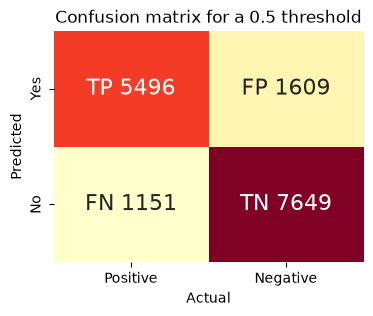

In [17]:
confusion_matrix_05 = compute_confusion_matrix(test_label, prediction_proba, 0.5 )
plt.figure(figsize = (4,3)) 
ax = plot_confusion_matrix(confusion_matrix_05)
plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion matrix for a 0.5 threshold')

prediction_proba = logistic.predict_proba(test_features_std)
This applies the trained model to the test set, data it has never seen.

Input: test_features_std, the standardized test features (n_test rows, same columns as in training).
Output: a numpy array of shape (n_test, 2), one row per animal:

[[0.82, 0.18],    ← P(not adopted), P(adopted)
 [0.35, 0.65],
 ...]
Each row sums to 1. The column order follows logistic.classes_, which is [0, 1], so column 1 = P(adopted).
The code keeps the probabilities rather than calling .predict(), so you can choose the threshold yourself afterwards.

The confusion matrix block

confusion_matrix_05 = compute_confusion_matrix(test_label, prediction_proba, 0.5)
This uses the helper from before. It compares P(adopted) > 0.5 with the true test labels and counts TP / FP / FN / TN. That gives the 2×2 array [[TP, FP], [FN, TN]]. The _05 in the name is for threshold 0.5; with that threshold the result is the same as .predict().


plt.figure(figsize=(4,3))
This starts a new, small figure (4×3 inches) so the heatmap isn't drawn into a previous plot.


ax = plot_confusion_matrix(confusion_matrix_05)
This draws the annotated heatmap. sn.heatmap returns the axes, which are stored in ax in case you want to customize them further.


plt.xlabel('Actual')
plt.ylabel('Predicted')
plt.title('Confusion matrix for a 0.5 threshold')
These label the axes, matching the layout from before: columns = actual (Positive / Negative), rows = predicted (Yes / No).

How to read the plot
Diagonal (TP top-left, TN bottom-right): correct predictions. You want these large (dark).
Off-diagonal (FP top-right, FN bottom-left): errors.
If FN is much larger than FP, the model is "too cautious": it misses many adoptions, so recall is low. Lowering the threshold, e.g. to 0.3, moves predictions from FN into TP, but also from TN into FP.

In [18]:
[t, accuracy, precision_positive, recall_positive, F1_score_positive, \
    precision_negative, recall_negative, F1_score_negative] = compute_all_score(confusion_matrix_05)

print("The accuracy of this model is {0:1.3f}".format(accuracy))
print("For the positive case, the precision is {0:1.3f}, the recall is {1:1.3f} and the F1 score is {2:1.3f}"\
      .format(precision_positive, recall_positive, F1_score_positive))
print("For the negative case, the precision is {0:1.3f}, the recall is {1:1.3f} and the F1 score is {2:1.3f}"\
      .format(precision_negative, recall_negative, F1_score_negative))

The accuracy of this model is 0.826
For the positive case, the precision is 0.774, the recall is 0.827 and the F1 score is 0.799
For the negative case, the precision is 0.869, the recall is 0.826 and the F1 score is 0.847


[t, accuracy, precision_positive, recall_positive, F1_score_positive, \
    precision_negative, recall_negative, F1_score_negative] = compute_all_score(confusion_matrix_05)
compute_all_score returns a list of 8 values. The list of 8 names on the left assigns them by position: the first value goes to t, the second to accuracy, and so on. It's the same unpacking as [[TP, FP],[FN, TN]] = ... before. The number of names must match the number of values, otherwise you get a ValueError.
The \ at the end of a line means the statement continues on the next line. Here it isn't strictly necessary, because Python already continues automatically inside open brackets.
t is just 0.5, the default, and isn't used afterwards.
Formatted printing

print("The accuracy of this model is {0:1.3f}".format(accuracy))
{0:1.3f} is a format specification:

0 means the first argument of .format(...), 1 the second, and so on
1.3f means a float (f) with 3 decimals; the 1 is the minimum width and doesn't matter here
the result looks like 0.821
The f-string equivalent is f"The accuracy of this model is {accuracy:.3f}".

The other two prints do the same with three values each ({0}, {1}, {2}). As before, the \ before .format only continues the line.

Solution output, and how to read it

The accuracy of this model is 0.821
For the positive case, the precision is 0.774, the recall is 0.816 and the F1 score is 0.794
For the negative case, the precision is 0.860, the recall is 0.825 and the F1 score is 0.842
Accuracy 0.82: 82% of the test animals are classified correctly.
Positive (adopted):
precision 0.77 → when the model says "adopted", it's right 77% of the time
recall 0.82 → it finds 82% of the animals that really were adopted
Negative (not adopted):
precision 0.86 and recall 0.83, so the model is somewhat better on this class
this is typical when the negative class is a bit larger, because the model sees more examples of it
The F1 scores of both classes are fairly close (0.79 vs 0.84). The model doesn't completely neglect one class, which would happen with strong class imbalance.


### C) Vary the value of the threshold in the range from 0 to 1 and visualize the value of accuracy, precision, recall, and F1-score (with respect to both classes) as a function of the threshold.

In [19]:
threshold = np.linspace(0, 1, 100)

What is the threshold?

It's the cut-off on the predicted probability:

$$\text{predict } 1 \text{ (adopted)} \iff P(\text{adopted}) > t$$

otherwise predict 0. With t = 0.5 you get the default behaviour of .predict(). Choosing t lets you decide how "eager" the model is to say yes:

Low t (e.g. 0.2): it says "adopted" for almost any hint. Few misses (high recall), but many false alarms (lower precision).
High t (e.g. 0.8): it only says "adopted" when it's very confident. Few false alarms (high precision), but it misses more (lower recall).

The model and its probabilities stay exactly the same. Only the decision rule on top changes.

Each of these 100 values is a candidate threshold. In the next step the solution loops over them, and for each t it computes the confusion matrix and compute_all_score(cm, t). That gives 100 rows of scores, which you can plot against t to see how accuracy, precision, recall and F1 change.

In [20]:
columns_score_name = ['Threshold', 'Accuracy', 'Precision P', 'Recall P', 'F1 score P', \
                                              'Precision N', 'Recall N', 'F1 score N']
threshold_score = pd.concat([pd.DataFrame([compute_all_score(compute_confusion_matrix(test_label, prediction_proba, t ),t)]\
                                             , columns=columns_score_name) for t in threshold], ignore_index=True)
threshold_score.set_index('Threshold', inplace=True)

This cell builds a table with one row per threshold (100 rows) and one column per score. It's a dense one-liner, so it's easiest to read from the inside out.

Column names

columns_score_name = ['Threshold', 'Accuracy', 'Precision P', 'Recall P', 'F1 score P',
                      'Precision N', 'Recall N', 'F1 score N']
There are 8 names, in the same order as the 8 values returned by compute_all_score. P = positive (adopted), N = negative.



The big line, from the inside out

compute_confusion_matrix(test_label, prediction_proba, t)
① This gives the 2×2 confusion matrix for one threshold t.


compute_all_score( ①, t)
② This turns the matrix into the list of 8 scores, [t, acc, prec_P, …]. Here t is passed in so it ends up in the first position.


pd.DataFrame([ ② ], columns=columns_score_name)
③ This turns that list into a DataFrame with 1 row. The extra [ ] around the list matters: [[a, b, c]] means 1 row with 3 columns, while a plain [a, b, c] would be read as 3 rows.


[ ③ for t in threshold ]
④ This list comprehension repeats ③ for all 100 thresholds, giving a list of 100 one-row DataFrames.


pd.concat( ④ , ignore_index=True)
⑤ This stacks them vertically into one DataFrame with 100 rows. ignore_index=True renumbers the rows 0…99; otherwise every row would keep its own index 0.

Setting the index

threshold_score.set_index('Threshold', inplace=True)
This makes the Threshold column the row index. That's useful because:

threshold_score.plot() then automatically puts the threshold on the x-axis and draws one line per score.
You can look up rows by threshold, e.g. threshold_score['F1 score P'].idxmax() gives the threshold with the best F1.


In [21]:
#Same thing, written more readably

rows = []
for t in threshold:
    cm = compute_confusion_matrix(test_label, prediction_proba, t)
    rows.append(compute_all_score(cm, t))

threshold_score = pd.DataFrame(rows, columns=columns_score_name).set_index('Threshold')


This version is also faster. It builds the DataFrame once from a list of lists instead of creating 100 small DataFrames and concatenating them.

Result (schematically):

Threshold	Accuracy	Precision P	Recall P	…
0.000	0.42	0.42	1.00	…
0.010	…	…	…	…
…				
1.000	0.58	NaN	0.00	…


Text(0.5, 1.0, 'Accuracy')

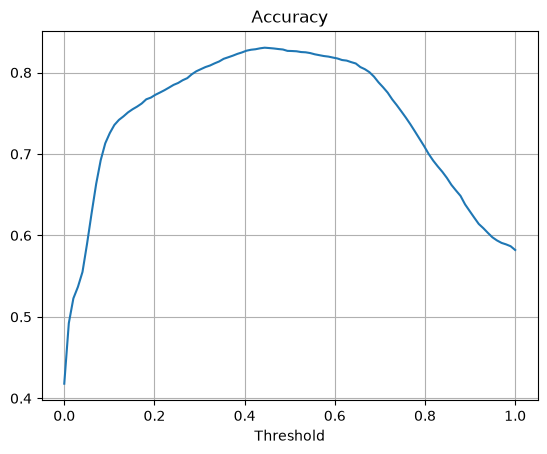

In [22]:
threshold_score['Accuracy'].plot(grid=True).set_title('Accuracy')

This one line plots accuracy as a function of the threshold.


threshold_score['Accuracy']
This selects the Accuracy column. Its result is a Series, and its index is the threshold, thanks to the set_index('Threshold') before.


.plot(grid=True)
This is the pandas shortcut for matplotlib. For a Series, it draws:

x-axis: the index, i.e. the threshold from 0 to 1
y-axis: the values, i.e. the accuracy
grid=True adds grid lines so you can read values off more easily. .plot() returns the matplotlib Axes.


.set_title('Accuracy')
This sets the title, called directly on the returned Axes. It's method chaining, the same as:


ax = threshold_score['Accuracy'].plot(grid=True)
ax.set_title('Accuracy')
What you should see
At t = 0: everything is predicted "adopted", so accuracy = the share of adopted animals (about 0.4).
At t = 1: nothing is predicted "adopted", so accuracy = the share of non-adopted animals (about 0.6).
In between: a hump, with the maximum somewhere around 0.5 (≈ 0.82). Thresholds near the middle sort best overall.

<Axes: xlabel='Threshold'>

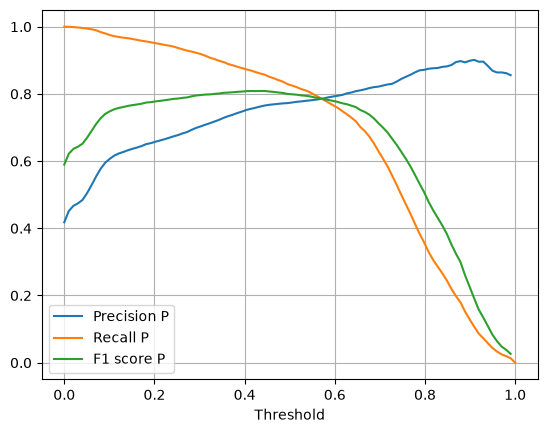

In [23]:
threshold_score[['Precision P', 'Recall P', 'F1 score P']].plot(grid=True)


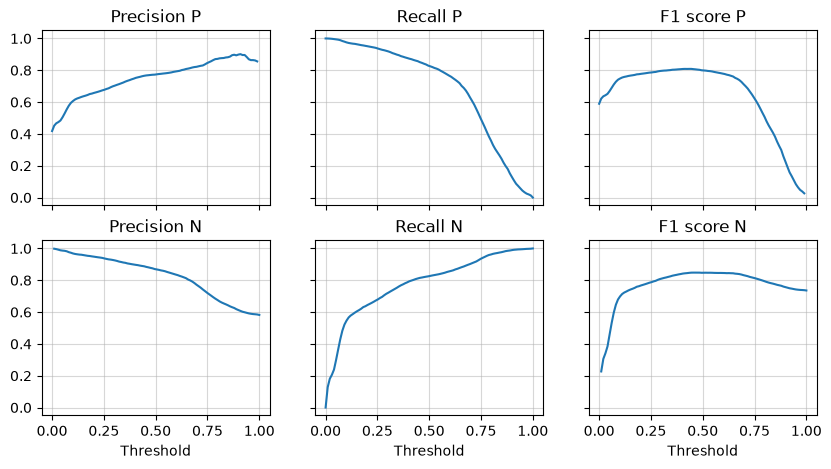

In [24]:
fig, axs = plt.subplots(nrows=2, ncols=3, sharex=True, sharey=True, figsize=(10,5))

col_plot = ['Precision P', 'Recall P', 'F1 score P', 'Precision N', 'Recall N', 'F1 score N']

major_ticks = np.linspace(0,1,5)

for axe, col in zip(axs.flat, col_plot):
    threshold_score[col].plot(ax=axe, grid = True)
    axe.set_title(col)
    axe.set_xticks(major_ticks)    
    axe.grid(which='major', alpha=0.5)

This cell draws 6 small plots in a 2×3 grid, one per score. The top row is for the positive class (adopted) and the bottom row for the negative class.


fig, axs = plt.subplots(nrows=2, ncols=3, sharex=True, sharey=True, figsize=(10,5))
This creates 2 rows × 3 columns of subplots, so axs is a 2×3 array of Axes.
sharex=True and sharey=True give all plots the same x- and y-range, which makes the curves directly comparable (all thresholds 0–1, all scores 0–1). Inner tick labels are hidden to save space.
figsize=(10,5) is the size in inches.

col_plot = ['Precision P', 'Recall P', 'F1 score P', 'Precision N', 'Recall N', 'F1 score N']
These are the 6 columns to plot. The first 3 fill the top row and the last 3 the bottom row.


major_ticks = np.linspace(0, 1, 5)
This gives [0, 0.25, 0.5, 0.75, 1], the positions of the x-axis ticks. linspace again, now with 5 points.

for axe, col in zip(axs.flat, col_plot):
axs.flat walks through the 2D array row by row as if it were 1D: top-left, top-middle, top-right, bottom-left, and so on. It's the same idea as axs[i//3][i%3], which you used with i//4 in exercise 2, but simpler.
zip(...) pairs the elements of both sequences: (subplot 1, 'Precision P'), (subplot 2, 'Recall P'), … So each loop iteration gets one subplot and one column name.

    threshold_score[col].plot(ax=axe, grid=True)
This plots that score against the threshold. ax=axe tells pandas to draw into this specific subplot; without it, pandas would create a new figure each time.


    axe.set_title(col)
    axe.set_xticks(major_ticks)
    axe.grid(which='major', alpha=0.5)
These set the title to the score name, put x-ticks at 0, 0.25, 0.5, 0.75 and 1, and draw the grid lines at those ticks semi-transparent (alpha=0.5).

What you should see
Low threshold → high threshold
Precision P	↗ rises: fewer but more certain "adopted" predictions (becomes NaN near t = 1)
Recall P	↘ falls from 1 to 0: more and more adoptions are missed
F1 P	hump: best balance somewhere in the middle
Precision N	↘ falls: "not adopted" predictions get diluted with real adoptions
Recall N	↗ rises from 0 to 1: more and more non-adoptions are caught
F1 N	hump
The negative row is the mirror image of the positive row. Raising the threshold moves animals from "predicted yes" to "predicted no", which helps one class's recall and hurts the other's. This is the precision–recall trade-off, and these plots are what you use to choose a threshold that fits your goal.

### D) Plot in a bar chart the coefficients of the logistic regression sorted by their contribution to the prediction.

What are the coefficients?

The model computes

$$\log\text{odds}(\text{adopted}) = w_0 + w_1 x_1 + w_2 x_2 + \dots$$

There is one weight $w_j$ per feature. Each one says how much the log odds of adoption change when that feature goes up by one unit. Since you standardized the features, one unit = one standard deviation, so the weights are on the same scale and you can compare them directly. That's the whole point of this task: which features drive adoption the most, and in which direction?

Sign: + means a higher value makes adoption more likely; − means less likely.
Size |w|: how strong the influence is. "Sorted by contribution" means sorting by this.
Plan
Get the weights. The fitted model stores them in an attribute ending in _ (like intercept_). Look at its shape: for binary classification it's 2D, (1, n_features), so you have to take the first row.
Get the matching names. The weights have the same order as the columns of the DataFrame you passed to fit. Which DataFrame was that?
Combine them into a pandas Series (values = weights, index = feature names). Then sorting and plotting keep the names attached automatically.
Sort. Two reasonable choices:
by value: largest negative to largest positive. Easy to read: one side discourages adoption, the other encourages it.
by absolute value: strongest influence first, regardless of direction. Hint: Series have .abs(), and sort_values takes a key= argument.
Plot a bar chart. With many features, a horizontal bar chart (barh) is much more readable, because the long dummy names fit on the y-axis.
Questions for the interpretation afterwards
Which features have the largest positive and negative weights? Do they make sense? (Think about sex/neutered status, age, intake condition…)
Do some dummies come in pairs that "mirror" each other? Remember that one-hot encoding with all categories makes the columns redundant, because they always sum to 1.
Is a large weight the same as causation? (Remember exercise 5.)

In [25]:
logistic = LogisticRegression(solver='lbfgs', max_iter=10000)
logistic.fit(train_features_std, train_label)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",10000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use 

In [26]:
tmp = []
for name, value in zip(train_features_std.columns, logistic.coef_[0]):
    tmp.append({"name": name, "value": value})
    
features_coef = pd.DataFrame(tmp).sort_values("value")
features_coef.head()

,name,value
1,age_upon_intake_(years),-2.025785
6,sex_upon_outcome_Intact Male,-0.773188
26,intake_type_Wildlife,-0.684676
5,sex_upon_outcome_Intact Female,-0.682420
31,sex_upon_intake_Unknown,-0.476937


This cell pairs each coefficient with its feature name and puts them into a DataFrame sorted by value. It's steps 1–4 from my plan.


tmp = []
This is an empty list to collect the rows.


for name, value in zip(train_features_std.columns, logistic.coef_[0]):
train_features_std.columns holds the feature names, in the order the model saw them during fit.
logistic.coef_ has shape (1, n_features), one row because the problem is binary. [0] takes that row, so you get a 1D array with one weight per feature.
zip pairs them by position: (name 1, weight 1), (name 2, weight 2), … That only works because the order is the same, which sklearn guarantees.

    tmp.append({"name": name, "value": value})
Each pair becomes a dict, which represents one future row. Keys = column names, values = cell contents.


features_coef = pd.DataFrame(tmp).sort_values("value")
pd.DataFrame(list_of_dicts) builds a table: each dict is a row, and the keys become the columns name and value.
.sort_values("value") sorts ascending: the most negative coefficient first (strongest against adoption) and the most positive last (strongest for adoption).
So the solution sorts by value, not by absolute value. That's the first of the two options I mentioned.


features_coef.head()
This shows the first 5 rows, i.e. the 5 features that lower the adoption probability the most. .tail() would show the ones that raise it the most.

Shorter alternative
A Series does the same thing in one line, with the names as index:


features_coef = pd.Series(logistic.coef_[0], index=train_features_std.columns).sort_values()
features_coef.plot.barh(figsize=(6, 10))
For the solution's DataFrame version, you'd plot it with something like plt.barh(features_coef['name'], features_coef['value']).

<BarContainer object of 32 artists>

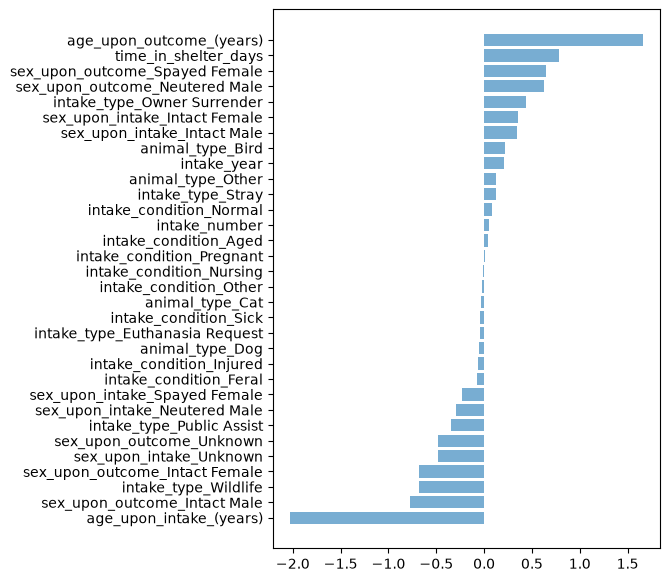

In [27]:
plt.subplots(figsize=(5,7))
plt.barh(features_coef.name, features_coef.value, alpha=0.6)


## Question 1: Which of the following metrics is most suitable when you are dealing with unbalanced classes?

- a) F1 Score
- b) Recall
- c) Precision
- d) Accuracy

F1 score, beacuse very unbalcnced sets favour that either recall or the precision of this group is dominated by oversize population. The accuracy is also not best metric because since unbalanced one might think to find a good threshold which then gives very bad recall or precision. so F1 score is best because it judges the tradeofff of recall and precsion.

a) F1 score is correct. Your reasoning points the right way but is a bit vague in places. The key arguments are:

Accuracy is dominated by the majority class. With 99% negatives, the trivial classifier "always predict no" already gets 99% accuracy while finding zero positives. A high accuracy therefore says almost nothing about the rare class.
Precision or recall alone can be gamed.
Recall: predict everything as positive → recall = 1, but precision is terrible.
Precision: predict only the single most certain case as positive → precision can be 1, but recall ≈ 0.
F1 combines both. It's the harmonic mean of precision and recall, so it's only high if both are high. It also doesn't use the true negatives (TN), which are the huge majority class that inflates accuracy.
Suggested answer:

a) F1 score. With unbalanced classes, accuracy is dominated by the majority class: a trivial classifier that always predicts the majority class already reaches a high accuracy while never detecting the minority class. Precision and recall alone are also not sufficient, since each can be made high at the cost of the other (predicting everything as positive gives recall = 1; predicting only very few positives can give high precision). The F1 score is the harmonic mean of precision and recall, so it is only high if both are high, and it does not depend on the (large) number of true negatives. It therefore reflects the performance on the minority class much better.

## Question 2: You are working on a binary classification problem. You trained a model on a training dataset and got the following confusion matrix on the test dataset. What is true about the evaluation metrics (rounded to the second decimal point):

|            | Pred = NO|Pred=YES|
|------------|----------|--------|
| Actual NO  |    50    |   10   |
| Actual YES |    5     |   100  |

- a) Accuracy is 0.95
- b) Accuracy is 0.85
- c) False positive rate is 0.95
- d) True positive rate is 0.95

**IMPORTANT**
No, the positive class is still YES. Which class is "positive" is defined by the problem (YES = the event you're detecting), not by where it sits in the table. This table only uses a different layout:

rows = actual, columns = predicted (the sklearn convention, and the opposite of the solution's helper function)
NO comes first, so TP sits bottom-right, not top-left
Don't go by position. Read each cell by its labels:

Pred = NO	Pred = YES
Actual NO	50 → TN (correctly said no)	10 → FP (said yes, was no)
Actual YES	5 → FN (said no, was yes)	100 → TP (correctly said yes)


In [28]:
#(TP + TN) / total 
# 
accuracy = (100+ 50)/ (50+5+10+100)

print("Accuracy: ", np.round(accuracy,2))

Accuracy:  0.91


a and b are wrong

In [29]:
# False positive rate: FP / (FP + TN)

false_pos = 10/(50+10)
print("false positive positive: ", np.round(false_pos,2))


false positive positive:  0.17


In [30]:
# True positive rate: True positive rate (recall) = TP / (TP + FN)
recall = 100/(100+5)
print("True positive rate (recall): ", np.round(recall,2))


True positive rate (recall):  0.95


answer **d** is correct!

**IMPORTANT**
Tip for exams: for any confusion matrix, first label the 4 cells TP/TN/FP/FN using "predicted vs actual", then compute. Never rely on position, because every textbook and library places them differently.